# SAML-D: dataset analysis and the strategic-launderer experiment

This notebook explores the SAML-D synthetic anti-money-laundering dataset (Oztas et al., 2023) and runs the supervisor's experiment: a detection control commits to a rule, the launderer switches to whichever pattern gets through, and we measure how much illicit value goes undetected.

Run the cells from top to bottom. If `SAML-D.csv` is not in the same folder as this notebook, the "Get the dataset" cell downloads it.

## 1. Setup

**Install packages.** Installs the Python packages this notebook needs, so nothing has to be set up beforehand. The versions are the ones the notebook was tested with:

| Package | Version |
|---|---|
| numpy | 2.4.6 |
| pandas | 3.1.0 |
| pyarrow | 26.0.0 |
| matplotlib | 3.11.2 |

For each package the cell checks the installed version and installs only what is missing or different, so re-running it is quick. It needs Python 3.11 or newer and an internet connection the first time. `ipykernel` is not listed because the notebook cannot run without it, so it is already present.

If the cell says to restart the kernel, do that and run the notebook from the top.

**Imports.** NumPy for arrays, pandas for tables, Matplotlib for plots, `pyarrow` so pandas can read and write the Parquet cache, and `Path` to check whether cache files exist.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow
from pathlib import Path
import shutil
import urllib.request
import zipfile

**Helper functions.** This cell only *defines* functions, so it is safe to run before any data is loaded.

| Function | What it does |
|---|---|
| `rate_by(col)` | For each value of `col`: laundering `rate` (share of rows that are laundering), `positive` (number of laundering rows) and `rows` (all rows). Reads the global `transaction` table. |
| `add_day(df)` | Whole days since the first transaction in `df`. |
| `per_sender(df, typology)` | For one `Laundering_type`, one row per sender: distinct receivers, payments, first and last day, span in days and total value. |
| `control_A(amount, is_legit, budget)` | **Control A, size threshold.** Finds the lowest X that flags at most `budget` legitimate payments, then flags every payment with `Amount >= X`. |
| `distinct_receivers(df, W)` | For every payment, how many distinct receivers its sender paid in the same W-day window. This is the slow step. |
| `control_B(nr, is_legit, budget)` | **Control B, counterparty limit.** Finds the lowest K that flags at most `budget` legitimate payments, then flags payments whose sender has more than K receivers in that window. |
| `caught_missed(...)` | For each pattern, the illicit value caught and missed by a set of flags. It checks that caught + missed = total. |

In [2]:
# ================  Some Helpers  =====================

def rate_by(col):
    return (transaction.groupby(col, observed=True)['Is_laundering']
            .agg(rate='mean', positive='sum', rows='size')
            .sort_values('rate', ascending=False))

def add_day(df):
    """Whole days since the first transaction (used for episode spans and windows)."""
    return ((df['Timestamp'] - df['Timestamp'].min()).dt.total_seconds() // 86400).astype('int32')

# distinct receivers per sender, within each typology
def per_sender(df, topology):
    sub = df[df['Laundering_type'].astype('str') == topology].copy()
    sub['day'] = add_day(sub).loc[sub.index]
    g = sub.groupby('Sender_account', observed=True).agg(
        recv=('Receiver_account', 'nunique'),
        pay=('txn_id', 'size'),
        first=('day', 'min'),
        last=('day', 'max'),
        value=('Amount', 'sum'))
    g['span_days'] = g['last'] - g['first'] + 1
    return g

# ================  Control A and B  =====================

def control_A(amount, is_legit, budget):
    """Flag payments with Amount >= X; X = smallest value with <= budget legit payments flagged."""
    a = np.sort(amount[is_legit])[::-1]
    X = float(np.nextafter(a[budget], np.inf))
    return X, amount >= X

def distinct_receivers(df, W):
    """Distinct receivers of the sender within each W-day window, repeated on each of its payments."""
    key = pd.DataFrame({
        's': df['Sender_account'].to_numpy(),
        'w': (df['day'] // W).to_numpy(),
        'r': df['Receiver_account'].to_numpy()
    })
    return key.groupby(['s', 'w'])['r'].transform('nunique').to_numpy()

def control_B(nr, is_legit, budget):
    """Flag a sender's payments in a window when it has more than K distinct receivers;
    K = smallest integer with <= budget legit payments flagged."""
    cnt = np.bincount(nr[is_legit])
    for k in range(1, len(cnt)+1):
        if (cnt[k + 1:].sum() if k + 1 < len(cnt) else 0) <= budget:
            break
    return k, nr > k

def caught_missed(amount, flag, patterns, value):
    out = {}
    for p, m in patterns.items():
        caught = float(amount[flag & m].sum())
        assert abs(caught + (value[p] - caught) - value[p]) < 1e-6
        out[p] = {'caught_value': caught, 'missed_value': value[p] - caught,
                  'caught_share': caught / value[p] if value[p] != 0 else 0}
    return out

### Get the dataset

Makes sure `SAML-D.csv` is next to this notebook, so it also runs on a computer where the data was never downloaded.

- **If the file is already there** with the right size (996,168,850 bytes), the cell does nothing.
- **Otherwise** it downloads the public Kaggle archive (about 200 MB, usually under a minute), extracts the 1 GB CSV, checks its size and removes the archive. The zip format's own checksum is verified while extracting.

It uses only Python's standard library, so no Kaggle account, API key or extra package is needed. If the download fails, for example behind a firewall or proxy, the error message says where to download the file by hand.

Dataset: [SAML-D on Kaggle](https://www.kaggle.com/datasets/berkanoztas/synthetic-transaction-monitoring-dataset-aml), licence CC BY-NC-SA 4.0. Please cite: B. Oztas, D. Cetinkaya, F. Adedoyin, M. Budka, H. Dogan and G. Aksu, "Enhancing Anti-Money Laundering: Development of a Synthetic Transaction Monitoring Dataset", 2023 IEEE International Conference on e-Business Engineering (ICEBE), pp. 47–54, doi: 10.1109/ICEBE59045.2023.00028.

In [3]:
# ================  Get the dataset  =====================


CSV = Path('SAML-D.csv')
CSV_BYTES = 996_168_850                   
KAGGLE_PAGE = 'https://www.kaggle.com/datasets/berkanoztas/synthetic-transaction-monitoring-dataset-aml'
KAGGLE_URL = 'https://www.kaggle.com/api/v1/datasets/download/berkanoztas/synthetic-transaction-monitoring-dataset-aml'

if CSV.exists() and CSV.stat().st_size == CSV_BYTES:
    print(f'{CSV} found, nothing to download.')
else:
    if CSV.exists():
        print(f'{CSV} has an unexpected size ({CSV.stat().st_size:,} bytes), downloading a fresh copy.')
    archive, part = Path('SAML-D.zip'), Path('SAML-D.csv.part')
    try:
        print('Downloading SAML-D from Kaggle (about 200 MB)...')
        with urllib.request.urlopen(KAGGLE_URL, timeout=60) as resp, open(archive, 'wb') as out:
            total, done, step = int(resp.headers.get('Content-Length', 0)), 0, 0
            while chunk := resp.read(1 << 20):
                out.write(chunk)
                done += len(chunk)
                if total and done * 10 // total > step:         
                    step = done * 10 // total
                    print(f'  {done / 1e6:,.0f} of {total / 1e6:,.0f} MB')
        print('Extracting (about 1 GB)...')
        with zipfile.ZipFile(archive) as z, z.open('SAML-D.csv') as src, open(part, 'wb') as dst:
            shutil.copyfileobj(src, dst, 1 << 20)
        if part.stat().st_size != CSV_BYTES:
            raise ValueError(f'extracted file has {part.stat().st_size:,} bytes, expected {CSV_BYTES:,}')
        part.replace(CSV)
        print(f'Saved {CSV} ({CSV_BYTES / 1e9:.2f} GB).')
    except Exception as e:
        raise RuntimeError(f'Download failed: {e}\nDownload the file manually from {KAGGLE_PAGE} '
                           f'and put SAML-D.csv in the same folder as this notebook.') from e
    finally:
        archive.unlink(missing_ok=True)
        part.unlink(missing_ok=True)

SAML-D.csv found, nothing to download.


## 2. First look at the raw data

Loads the raw CSV (about 1 GB, 9.5 million rows) so the next four cells can inspect it as it comes from Kaggle. This is slow, and the cache cell in section 3 replaces this table anyway. Once the cache exists, this cell and the next four are optional.

In [4]:
transaction = pd.read_csv('SAML-D.csv')

**First five rows.** Each row is one transaction: time and date, sender and receiver account, amount, the currencies and bank locations on both sides, the payment type, the label `Is_laundering` (1 = laundering) and `Laundering_type`, the pattern that generated it.

In [5]:
transaction.head()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,2022-10-07,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,10:35:20,2022-10-07,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out
2,10:35:20,2022-10-07,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
3,10:35:21,2022-10-07,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4,10:35:21,2022-10-07,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits


**Summary of the numeric columns.**
- The account columns are identifiers, so their mean and spread mean nothing.
- `Amount` is heavily skewed: the median is about 6,100 but the maximum is about 12.6 million.
- The mean of `Is_laundering` is the laundering share: 0.00104, about 0.1%.

In [6]:
transaction.describe()

,Sender_account,Receiver_account,Amount,Is_laundering
count,9.504852e+06,9.504852e+06,9.504852e+06,9.504852e+06
mean,5.006619e+09,5.006006e+09,8.762968e+03,1.038733e-03
std,2.885814e+09,2.884763e+09,2.561495e+04,3.221263e-02
min,9.018000e+03,9.018000e+03,3.730000e+00,0.000000e+00
25%,2.513133e+09,2.513219e+09,2.143688e+03,0.000000e+00
50%,5.001017e+09,5.002572e+09,6.113720e+03,0.000000e+00
75%,7.505051e+09,7.502397e+09,1.045846e+04,0.000000e+00
max,9.999987e+09,9.999971e+09,1.261850e+07,1.000000e+00


**Column types and memory.** Eight columns are stored as text, and the table takes about 870 MB. That figure is pandas' quick estimate and undercounts text, so the real footprint is larger. Section 3 reduces it.

In [7]:
transaction.info()

<class 'pandas.DataFrame'>
RangeIndex: 9504852 entries, 0 to 9504851
Data columns (total 12 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   Time                    str    
 1   Date                    str    
 2   Sender_account          int64  
 3   Receiver_account        int64  
 4   Amount                  float64
 5   Payment_currency        str    
 6   Received_currency       str    
 7   Sender_bank_location    str    
 8   Receiver_bank_location  str    
 9   Payment_type            str    
 10  Is_laundering           int64  
 11  Laundering_type         str    
dtypes: float64(1), int64(3), str(8)
memory usage: 1.4 GB


**Class balance.** 9,494,979 normal transactions against 9,873 laundering ones (0.104%). This imbalance is why accuracy is a useless metric here: predicting "normal" for everything scores 99.9%.

In [8]:
transaction['Is_laundering'].value_counts(dropna=False)

Is_laundering
0    9494979
1       9873
Name: count, dtype: int64

## 3. Clean, compress and cache the dataset

This is the main data-preparation cell. It can be re-run safely.

**If the cache files exist** (`SAML-D.parquet` and `account_ids.npy`), it just loads them. That takes seconds.

**Otherwise it builds them from the CSV:**
1. Reads text columns with few distinct values as `category`, which stores each value once and is much smaller. `Amount` stays `float64` so sums of laundered value are exact.
2. Merges `Date` and `Time` into one `Timestamp`, needed for time windows and time-based splits.
3. Adds `txn_id`, the original row number, to break ties between equal timestamps.
4. Replaces account IDs with compact `int32` codes. The mapping back to the original IDs is saved in `account_ids.npy`.
5. Adds three flags: `is_normal_pattern` (the label in another form, never use it as a feature), `cross_border` (sender and receiver in different countries) and `currency_mismatch` (different currencies).
6. Saves both cache files.

If you change any of these steps, delete both cache files so they are rebuilt.

The output is the memory per column in MB. The whole table is now about 360 MB.

In [9]:
# ================  Memory optimization  =====================

PARQUET = Path('SAML-D.parquet')
IDS = Path('account_ids.npy')

if PARQUET.exists() and IDS.exists():
    transaction = pd.read_parquet(PARQUET)
    ids = np.load(IDS)
else:
    cat_cols = ['Payment_currency', 'Received_currency', 'Sender_bank_location',
                'Receiver_bank_location', 'Payment_type', 'Laundering_type']
    transaction = pd.read_csv(
        'SAML-D.csv',
        dtype={**{c: 'category' for c in cat_cols}, 'Is_laundering': 'int8'},  # Amount stays float64
    )

    transaction['Timestamp'] = pd.to_datetime(
        transaction['Date'] + ' ' + transaction['Time'], format='%Y-%m-%d %H:%M:%S')
    transaction = transaction.drop(columns=['Date', 'Time'])
    transaction.insert(0, 'txn_id', np.arange(len(transaction), dtype='int32')) 

    codes, uniques = pd.factorize(
        pd.concat([transaction['Sender_account'], transaction['Receiver_account']]))
    n = len(transaction)
    transaction['Sender_account'] = codes[:n].astype('int32')
    transaction['Receiver_account'] = codes[n:].astype('int32')
    ids = np.asarray(uniques)

    transaction['is_normal_pattern'] = transaction['Laundering_type'].astype(str).str.startswith('Normal')
    transaction['cross_border'] = transaction['Sender_bank_location'].astype(str) != transaction['Receiver_bank_location'].astype(str)
    transaction['currency_mismatch'] = transaction['Payment_currency'].astype(str) != transaction['Received_currency'].astype(str)

    transaction.to_parquet(PARQUET, index=False)
    np.save(IDS, ids)

(transaction.memory_usage(deep=True).sort_values(ascending=False) / 1e6).round(1)

Amount                    76.0
Timestamp                 76.0
Receiver_account          38.0
txn_id                    38.0
Sender_account            38.0
Laundering_type            9.5
Sender_bank_location       9.5
Receiver_bank_location     9.5
Payment_currency           9.5
Received_currency          9.5
Payment_type               9.5
Is_laundering              9.5
cross_border               9.5
is_normal_pattern          9.5
currency_mismatch          9.5
Index                      0.0
dtype: float64

**Integrity checks.** Each `assert` stops the notebook with an error if the data is not as expected:
- rows are in time order;
- `is_normal_pattern` matches the label exactly;
- there are no missing values and no duplicate rows.

It then prints the shape and memory and lists the final column types.

In [10]:
assert transaction['Timestamp'].is_monotonic_increasing
assert (transaction['is_normal_pattern'] == (transaction['Is_laundering'] == 0)).all()
assert transaction.isna().sum().sum() == 0
assert not transaction.duplicated().any()
print(f"data shape: {transaction.shape}, memory: {transaction.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(f"Amount range: {transaction['Amount'].dtype}")
transaction.dtypes

data shape: (9504852, 15), memory: 361.2 MB
Amount range: float64


txn_id                             int32
Sender_account                     int32
Receiver_account                   int32
Amount                           float64
Payment_currency                category
Received_currency               category
Sender_bank_location            category
Receiver_bank_location          category
Payment_type                    category
Is_laundering                       int8
Laundering_type                 category
Timestamp                 datetime64[us]
is_normal_pattern                   bool
cross_border                        bool
currency_mismatch                   bool
dtype: object

## 4. The labels

**`Laundering_type` leaks the label.** The cross-table counts rows per type and label. Every `Normal_*` type has only 0s and every other type has only 1s, so this column gives the answer away. It must never be a model feature; we keep it only to evaluate results per pattern.

Only the last line's table is shown. The `groupby` line above it is computed but not displayed.

In [11]:
# ================  Laundering_type leaks the label  =====================

transaction.groupby(['Is_laundering', 'Laundering_type'], observed=True).size()
pd.crosstab(transaction['Is_laundering'], transaction['Laundering_type']).T

Is_laundering,0,1
Laundering_type,,
Behavioural_Change_1,0,394
Behavioural_Change_2,0,345
Bipartite,0,383
Cash_Withdrawal,0,1334
Cycle,0,382
Deposit-Send,0,945
Fan_In,0,364
Fan_Out,0,237
Gather-Scatter,0,354


**Laundering rows per typology.** Keeps only the 9,873 laundering rows and counts them by pattern. Structuring is the most common (1,870) and Over-Invoicing the rarest (54). The `Normal_*` types show 0 because `category` columns keep all their categories even when a subset has none.

In [12]:
sus = transaction[transaction['Is_laundering'] == 1]

sus['Laundering_type'].value_counts()

Laundering_type
Structuring               1870
Cash_Withdrawal           1334
Deposit-Send               945
Smurfing                   932
Layered_Fan_In             656
Layered_Fan_Out            529
Stacked Bipartite          506
Behavioural_Change_1       394
Bipartite                  383
Cycle                      382
Fan_In                     364
Gather-Scatter             354
Behavioural_Change_2       345
Scatter-Gather             338
Single_large               250
Fan_Out                    237
Over-Invoicing              54
Normal_Cash_Deposits         0
Normal_Cash_Withdrawal       0
Normal_Fan_In                0
Normal_Fan_Out               0
Normal_Foward                0
Normal_Group                 0
Normal_Mutual                0
Normal_Periodical            0
Normal_Plus_Mutual           0
Normal_Small_Fan_Out         0
Normal_single_large          0
Name: count, dtype: int64

**Separate the label, the typology and the features.** Splitting them now means the label cannot leak into a model by accident:
- `label` is the target,
- `topology` is the laundering type, kept for per-pattern evaluation,
- `feature` is everything else.

The block in triple quotes is a string, not code that runs. It is a template for later, for measuring recall per pattern once a model exists. `test_idx` and `pred` are not defined yet.

In [13]:
# ================  Separating Laundering Types: avoid leaks  =====================



label = transaction['Is_laundering']
topology = transaction['Laundering_type']
feature = transaction.drop(columns=['Is_laundering', 'Laundering_type'])

'''
# A single overall recall can hide weak spots. The model might catch 95% of
# Smurfing but only 20% of Fan_Out, and the overall number would still look fine.
# This breakdown shows which laundering patterns the model struggles with.

pd.DataFrame({
    'topology': topology[test_idx], 
    'label': label[test_idx], 
    'pred': pred
}).query('label == 1').groupby('topology', observed=True)['pred'].mean()

'''

"\n# A single overall recall can hide weak spots. The model might catch 95% of\n# Smurfing but only 20% of Fan_Out, and the overall number would still look fine.\n# This breakdown shows which laundering patterns the model struggles with.\n\npd.DataFrame({\n    'topology': topology[test_idx], \n    'label': label[test_idx], \n    'pred': pred\n}).query('label == 1').groupby('topology', observed=True)['pred'].mean()\n\n"

## 5. Where laundering concentrates

Runs `rate_by` on five columns. How to read each table:
- `rate` is the risk per transaction, to compare with the 0.104% baseline;
- `positive` is how much of the laundering falls in that group;
- `rows` is how much to trust the rate. A rate from a few hundred rows is noisy.

The comments below the code summarise the findings: cash and cross-border payments, and receivers in high-risk countries, are several times above the baseline.

Some characters in the comments were garbled when pasted (they show as �). The intended signs are × and –.

In [14]:
for col in ['Payment_type', 'Sender_bank_location', 'Receiver_bank_location',
            'Payment_currency', 'Received_currency']:
    print(f'---- {col} --')
    display(rate_by(col))

# For the payment types,Cash Deposit is about 6× the baseline, 
# Cash Withdrawal about 4×, and Cross-border about 2.7×

# Receiver location is a strong signal because Non-UK receivers run 0.2–0.66% 
# including Nigeria, Morocco, Albania, UAE, Mexico, Turkey, Pakistan at the top, against 0.08% for UK.

# UK senders have 0.10%, near baseline. Non-UK senders are slightly higher, 
# but with only 25–55 positives each, so it's noisy.

# Currency columns are largely redundant. 9,253 of 9,873 positives (94%) are UK-originated, so most of the fraud is domestic. 
# Location alone won't find it, which fits the hard-negative picture from before.


---- Payment_type --


,rate,positive,rows
Payment_type,,,
Cash Deposit,0.006239,1405,225206
Cash Withdrawal,0.004440,1334,300477
Cross-border,0.002814,2628,933931
ACH,0.000577,1159,2008807
Credit card,0.000564,1136,2012909
Debit card,0.000559,1124,2012103
Cheque,0.000540,1087,2011419


---- Sender_bank_location --


,rate,positive,rows
Sender_bank_location,,,
Morocco,0.002983,55,18437
Mexico,0.002491,44,17662
Netherlands,0.002445,41,16770
India,0.002387,42,17596
Italy,0.002382,45,18895
Germany,0.002233,43,19259
Austria,0.002105,38,18050
Japan,0.002058,38,18468
Switzerland,0.002000,41,20503


---- Receiver_bank_location --


,rate,positive,rows
Receiver_bank_location,,,
Nigeria,0.006558,251,38272
Morocco,0.006537,253,38704
Albania,0.006059,235,38783
UAE,0.005432,195,35897
Mexico,0.005132,197,38385
Turkey,0.004974,177,35586
Pakistan,0.004336,169,38980
Netherlands,0.003966,148,37314
Austria,0.003965,154,38844


---- Payment_currency --


,rate,positive,rows
Payment_currency,,,
Moroccan dirham,0.003544,90,25395
Dirham,0.003264,89,27263
Swiss franc,0.002983,82,27492
Indian rupee,0.002758,68,24657
Mexican Peso,0.002736,68,24852
Turkish lira,0.002608,73,27996
Albanian lek,0.002583,64,24778
Yen,0.002543,65,25562
US dollar,0.002302,60,26061


---- Received_currency --


,rate,positive,rows
Received_currency,,,
Naira,0.006393,288,45046
Moroccan dirham,0.006230,285,45748
Albanian lek,0.005729,262,45736
Dirham,0.005257,225,42797
Mexican Peso,0.005193,235,45255
Turkish lira,0.005124,218,42545
Pakistani rupee,0.004435,204,45993
Indian rupee,0.003931,172,43757
Euro,0.003087,716,231911


**Engineered flags.** Rebuilds `currency_mismatch` and `cross_border`, which the cache cell already created, so this is harmless, and shows the laundering rate for each.
- `cross_border` rows are about 4× riskier than domestic ones (0.33% vs 0.08%).
- `currency_mismatch` rows are about 4.6× riskier (0.34% vs 0.07%).

In [15]:
transaction['currency_mismatch'] = (transaction['Payment_currency'] != transaction['Received_currency'])
transaction['cross_border'] = (transaction['Sender_bank_location'] != transaction['Receiver_bank_location'])

display(rate_by('currency_mismatch'))
display(rate_by('cross_border'))

,rate,positive,rows
currency_mismatch,,,
True,0.003368,3657,1085862
False,0.000738,6216,8418990


,rate,positive,rows
cross_border,,,
True,0.003259,3045,934348
False,0.000797,6828,8570504


**Plot of the laundering rate by payment type.** A visual version of the first table in section 5, sorted from highest to lowest rate.

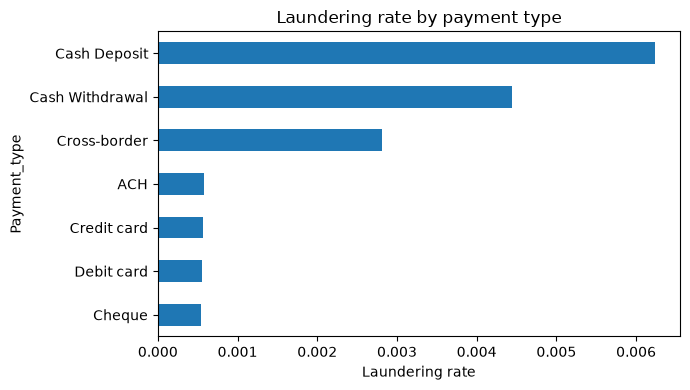

In [16]:
# Baseline: the overall rate is 0.104%. Anything several times higher is a useful signal.
# Rows that are always 0 or always 1 in a category are the strongest signal

r = rate_by('Payment_type')
r['rate'].plot.barh(figsize=(7, 4))
plt.xlabel('Laundering rate'); plt.title('Laundering rate by payment type') 
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

## 6. Amount

**Amount summary for normal vs laundering transactions.**
- The medians are similar (about 6,100 vs 5,300), so a typical laundering payment is ordinary in size.
- The laundering mean is about 5× higher because a few huge payments pull it up. That is why medians and percentiles describe the data better than means here.

The comments note two consequences: judge models with PR-AUC or recall at a fixed alert volume, not accuracy; and be wary of rules such as "amount > 1M means fraud", which come from how the data was generated.

In [17]:
# Amount is heavily skewed (median about 6k, max 12.6M). Because of this, I use log scale.

# We should judge models by PR-AUC, precision/recall at a set alert volume, or recall@k, not by accuracy or ROC-AUC.

# The laundering mean (40.6k) is pulled up by a few huge transactions, so it misrepresents the typical laundering transaction. 
# we should use medians and quantiles.

# If every amount over 1M is laundering, a tree model will learn the rule amount > 1M means fraud. 
# It will look great on this data and won’t hold up on real data.

# The laundering 75th percentile is 9,790, just under 10,000.
# That fits structuring, where amounts are kept below the $10k reporting threshold

q = [0, 0.25, 0.5, 0.75, 0.99]

display(transaction.groupby('Is_laundering')['Amount']
        .describe(q).round(1))

,count,mean,std,min,0%,25%,50%,75%,99%,max
Is_laundering,,,,,,,,,,
0,9494979.0,8729.9,21750.0,3.7,3.7,2142.9,6114.6,10459.0,44938.2,999962.2
1,9873.0,40587.7,419181.1,15.8,15.8,2723.8,5322.8,9789.7,419540.1,12618498.4


**Amount distribution.** Histograms of normal and laundering amounts on a logarithmic scale, because amounts range from a few units to millions.
- The bins are equally spaced on the log scale (`np.logspace`).
- `density=True` scales both histograms to the same area. Without it, the 9,873 laundering rows would be invisible next to 9.5 million normal ones.

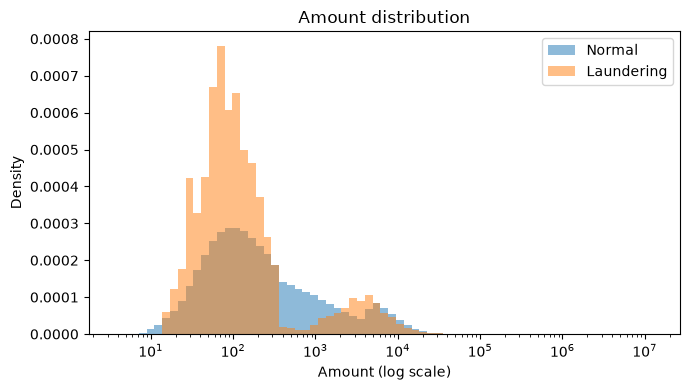

In [18]:
# ===============  Amount distribution  =====================

bins = np.logspace(np.log10(transaction['Amount'].min()), 
                   np.log10(transaction['Amount'].max()), 70)

lbl, ax = plt.subplots(figsize=(7, 4))
for lbl, name in [(0, 'Normal'), (1, 'Laundering')]:
    ax.hist(transaction.loc[transaction['Is_laundering'] == lbl, 'Amount'],
            bins=bins, alpha=0.5, label=name, density=True)
ax.set_xscale('log'); ax.set_xlabel('Amount (log scale)'); ax.set_ylabel('Density'); ax.set_title('Amount distribution')
ax.legend(); plt.tight_layout(); plt.show()

**Laundering rate by amount band.** Splits all transactions into 20 bands with the same number of rows each (`qcut`), then shows the rate per band in %.

The rate is U-shaped, not rising: highest for very small amounts (cash withdrawals), around 3,000 to 4,300 (structuring and smurfing) and for the largest amounts.

In [19]:
#  ===============   Laundering rate (%) by amount  =====================

band = pd.qcut(transaction['Amount'], 20, duplicates='drop')
b = transaction.groupby(band, observed=True)['Is_laundering'].agg(rate='mean', positive='sum', rows='size')
display(b.assign(rate=(b['rate'] * 100).round(3)))

,rate,positive,rows
Amount,,,
"(3.729, 217.3]",0.212,1008,475246
"(217.3, 508.16]",0.076,361,475244
"(508.16, 930.78]",0.012,55,475241
"(930.78, 1459.912]",0.044,210,475240
"(1459.912, 2143.688]",0.078,372,475242
"(2143.688, 3061.32]",0.162,772,475245
"(3061.32, 4323.17]",0.249,1185,475241
"(4323.17, 4911.8]",0.133,630,475244
"(4911.8, 5493.99]",0.101,479,475245


**Amount by typology**, first for laundering and then for normal transactions, sorted by median.

Some laundering patterns have the same amounts as their normal twin. Cash_Withdrawal and Normal_Cash_Withdrawal both have a median of 139, and Single_large matches Normal_single_large. Amount alone cannot separate these.

In [20]:
# ===============  Amount by typology =====================

for flag in [1, 0]:
    print(f'{"Laundering" if flag else "Normal"} transactions')
    sub = transaction[transaction['Is_laundering'] == flag]
    display(sub.groupby('Laundering_type', observed=True)['Amount']
        .describe(percentiles=[0, 0.25, 0.5, 0.75, 0.99]).round(0)
        .query('count > 0').sort_values('50%')[['count', 'mean', '50%', '75%', '99%', 'max']])

Laundering transactions


,count,mean,50%,75%,99%,max
Laundering_type,,,,,,
Cash_Withdrawal,1334.0,154.0,139.0,214.0,342.0,350.0
Smurfing,932.0,2803.0,2629.0,3428.0,6262.0,6985.0
Behavioural_Change_1,394.0,4879.0,3118.0,6682.0,18371.0,19276.0
Behavioural_Change_2,345.0,4916.0,3486.0,7043.0,18701.0,19607.0
Structuring,1870.0,5246.0,4800.0,6375.0,11317.0,12454.0
Deposit-Send,945.0,9181.0,6332.0,12014.0,36839.0,43910.0
Layered_Fan_Out,529.0,8629.0,6730.0,10367.0,32481.0,37748.0
Scatter-Gather,338.0,10672.0,7854.0,12132.0,44059.0,67635.0
Stacked Bipartite,506.0,9727.0,7883.0,11835.0,33534.0,44651.0


Normal transactions


,count,mean,50%,75%,99%,max
Laundering_type,,,,,,
Normal_Cash_Withdrawal,305031.0,153.0,139.0,215.0,342.0,350.0
Normal_Cash_Deposits,223801.0,2140.0,1758.0,3147.0,5825.0,6000.0
Normal_Small_Fan_Out,3477717.0,4704.0,2210.0,5821.0,31005.0,269227.0
Normal_Group,528351.0,5023.0,3440.0,6940.0,21091.0,27904.0
Normal_Periodical,210526.0,5942.0,4468.0,7780.0,22461.0,26499.0
Normal_Foward,42031.0,8119.0,6166.0,10655.0,30504.0,34971.0
Normal_Fan_Out,2302220.0,10089.0,8417.0,12106.0,31686.0,54072.0
Normal_Fan_In,2104285.0,10705.0,9007.0,12950.0,33061.0,50887.0
Normal_Plus_Mutual,155041.0,43274.0,13688.0,31615.0,586102.0,999946.0


**Median amount by payment type and typology.** A wide table with one row per payment type and one column per typology. Empty cells mean that combination never occurs.

In [21]:
display(transaction.groupby(['Payment_type', 'Laundering_type'], observed=True)['Amount'].median().unstack().round(0))

Laundering_type,Behavioural_Change_1,Behavioural_Change_2,Bipartite,Cash_Withdrawal,Cycle,Deposit-Send,Fan_In,Fan_Out,Gather-Scatter,Layered_Fan_In,...,Normal_Periodical,Normal_Plus_Mutual,Normal_Small_Fan_Out,Normal_single_large,Over-Invoicing,Scatter-Gather,Single_large,Smurfing,Stacked Bipartite,Structuring
Payment_type,,,,,,,,,,,,,,,,,,,,,
ACH,3332.0,NaN,7900.0,NaN,20112.0,9377.0,8050.0,11574.0,7840.0,11586.0,...,4461.0,13668.0,2212.0,180665.0,3753602.0,8654.0,136057.0,NaN,8784.0,5102.0
Cash Deposit,NaN,NaN,NaN,NaN,NaN,6268.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2629.0,NaN,NaN
Cash Withdrawal,NaN,NaN,NaN,139.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cheque,2841.0,NaN,9189.0,NaN,23604.0,6773.0,7678.0,9038.0,7485.0,10958.0,...,4438.0,13501.0,2211.0,185610.0,4609080.0,9014.0,229410.0,NaN,8013.0,4856.0
Credit card,3185.0,NaN,9304.0,NaN,17852.0,7383.0,9386.0,7720.0,8852.0,10823.0,...,4455.0,14110.0,2201.0,186407.0,4408472.0,7828.0,176342.0,NaN,8065.0,5324.0
Cross-border,3170.0,3486.0,8535.0,NaN,22560.0,6204.0,7731.0,9018.0,9772.0,9327.0,...,4547.0,13607.0,2245.0,181777.0,3409692.0,7001.0,132540.0,NaN,7096.0,4546.0
Debit card,2089.0,NaN,9354.0,NaN,20029.0,6676.0,9635.0,9177.0,8927.0,11477.0,...,4470.0,13607.0,2208.0,183759.0,4298118.0,7065.0,247143.0,NaN,7936.0,4935.0


## 7. Counterparties: laundering fan-out vs ordinary fan-out

Runs `per_sender` for labelled `Fan_Out` and for the two normal fan-out types. The columns are distinct receivers (`recv`), payments (`pay`), duration (`span_days`) and total value per sender.

Main finding: laundering fan-out is **narrower** than ordinary fan-out, with at most 10 receivers vs up to 20 or 30. Laundering senders pay each receiver once, while ordinary ones pay each about a dozen times. A limit on the number of receivers would therefore flag ordinary accounts first.

In [22]:
# ===============  counterparty analysis  =====================

for name in ['Fan_Out', 'Normal_Fan_Out', 'Normal_Small_Fan_Out']:
    print(f'--- {name} ---')
    display(per_sender(transaction,name)[['recv', 'pay', 'span_days', 'value']].describe().round(1))

--- Fan_Out ---


,recv,pay,span_days,value
count,29.0,29.0,29.0,29.0
mean,8.2,8.2,9.6,98988.0
std,1.6,1.6,1.5,38544.0
min,5.0,5.0,6.0,52277.3
25%,7.0,7.0,9.0,73342.7
50%,8.0,8.0,10.0,87788.2
75%,10.0,10.0,11.0,121923.3
max,10.0,10.0,12.0,221884.4


--- Normal_Fan_Out ---


,recv,pay,span_days,value
count,13039.0,13039.0,13039.0,13039.0
mean,13.6,176.6,2.0,1781344.8
std,4.0,53.0,0.1,602896.8
min,7.0,21.0,1.0,148948.2
25%,10.0,130.0,2.0,1290626.3
50%,14.0,182.0,2.0,1771377.8
75%,17.0,221.0,2.0,2235522.7
max,20.0,260.0,2.0,4092680.6


--- Normal_Small_Fan_Out ---


,recv,pay,span_days,value
count,16175.0,16175.0,16175.0,16175.0
mean,18.5,215.0,317.3,1011324.0
std,6.9,83.8,3.3,532167.5
min,6.0,36.0,276.0,46907.5
25%,12.0,144.0,316.0,602636.1
50%,19.0,214.0,318.0,947332.7
75%,24.0,283.0,319.0,1345040.4
max,30.0,435.0,321.0,4201390.3


## 8. Time

`t = transaction` does not copy the table: both names point to the same data, so the new columns are added to `transaction` too.

The cell:
1. adds `day` (days since the start), `month` and `hour`;
2. shows the laundering rate per month and per hour. Both are flat at about 0.1%, so a time-based train/test split is safe;
3. shows, per typology, how many days each sender's laundering lasts. Fan-out takes about 10 days, while smurfing takes about four months.

In [23]:
t = transaction

t['day'] = ((t['Timestamp'] - t['Timestamp'].min()).dt.total_seconds() // 86400).astype('int32')
t['month'] = t['Timestamp'].dt.to_period('M')
t['hour'] = t['Timestamp'].dt.hour

for col in ['month', 'hour']:
    r = t.groupby(col)['Is_laundering'].agg(rate='mean', positive='sum', rows='size')
    display(r.assign(rate=(r['rate'] * 100).round(3)))

s = t[t['Is_laundering'] == 1]
g = s.groupby(['Laundering_type', 'Sender_account'], observed=True)['day'].agg(first='min', last='max')
g['span'] = g['last'] - g['first'] + 1
display(g.groupby(level=0)['span'].describe()[['count', 'mean', 'min', '50%', 'max']].round(1))

,rate,positive,rows
month,,,
2022-10,0.098,694,708654
2022-11,0.088,794,897621
2022-12,0.101,907,900341
2023-01,0.103,940,908320
2023-02,0.105,946,904806
2023-03,0.102,927,908562
2023-04,0.107,962,902883
2023-05,0.094,866,917601
2023-06,0.114,1024,897243


,rate,positive,rows
hour,,,
0,0.112,136,121548
1,0.100,122,121964
2,0.113,138,121627
3,0.114,138,121282
4,0.104,126,121568
5,0.115,140,122114
6,0.120,146,121484
7,0.156,222,142497
8,0.117,632,538992


,count,mean,min,50%,max
Laundering_type,,,,,
Behavioural_Change_1,53.0,8.6,3.0,9.0,11.0
Behavioural_Change_2,59.0,8.0,1.0,9.0,11.0
Bipartite,74.0,11.4,3.0,12.0,17.0
Cash_Withdrawal,88.0,126.3,5.0,132.0,314.0
Cycle,382.0,1.0,1.0,1.0,1.0
Deposit-Send,563.0,33.7,1.0,1.0,311.0
Fan_In,364.0,1.0,1.0,1.0,1.0
Fan_Out,29.0,9.7,6.0,10.0,12.0
Gather-Scatter,210.0,2.1,1.0,1.0,11.0


## 9. The experiment

**Setup.** Prepares the inputs both controls need:
- `amt` is the amounts and `is_legit` marks the legitimate payments;
- `patterns` marks the payments of the two patterns studied, Smurfing and Fan_Out;
- `value` is each pattern's total illicit value, with each payment counted once;
- `nr_by_window` holds the distinct receivers per sender for 7-, 14- and 30-day windows. This is the slow step, run once here.

In [24]:
# ===============  setup  =====================

if 'day' not in transaction.columns:
    transaction['day'] = ((transaction['Timestamp'] - transaction['Timestamp'].min())
                          .dt.total_seconds() // 86400).astype('int32')

amt = transaction['Amount'].to_numpy()
is_legit = (transaction['Is_laundering'] == 0).to_numpy()
ltype = transaction['Laundering_type'].astype(str)
patterns = {'Smurfing': (ltype == 'Smurfing').to_numpy(),
            'Fan_Out':  (ltype == 'Fan_Out').to_numpy()}
value = {p: float(amt[m].sum()) for p, m in patterns.items()}

WINDOWS = [7, 14, 30]
nr_by_window = {W: distinct_receivers(transaction, W) for W in WINDOWS}   # slow step, run once

print("legit payments:" + str(int(is_legit.sum())) + "| pattern value:" + str({p: round(v) for p, v in value.items()}))

legit payments:9494979| pattern value:{'Smurfing': 2612341, 'Fan_Out': 2870652}


**Quick check at one budget.** Calibrates both controls to flag at most 1,000 legitimate payments and shows what Control B (30-day window) catches.

The first line recomputes `nr_by_window`, which the previous cell already did, so it costs time for nothing. It can be deleted.

In [25]:
# ===============  Control A and B  =====================

nr_by_window = {W: distinct_receivers(transaction, W) for W in [7, 14, 30]}

X, fA = control_A(amt, is_legit, 1_000)
k, fB = control_B(nr_by_window[30], is_legit, 1_000)
caught_missed(amt, fB, patterns, value)

{'Smurfing': {'caught_value': 0.0,
  'missed_value': 2612340.72,
  'caught_share': 0.0},
 'Fan_Out': {'caught_value': 0.0,
  'missed_value': 2870651.7600000002,
  'caught_share': 0.0}}

**Static comparison.** For each budget (the number of legitimate payments a control may flag), calibrates both controls and records:
- the threshold, X for A and K for B;
- how many legitimate payments are actually flagged;
- the share of smurfing and fan-out value caught.

Control B is run for each window size. The result is one table, `static`.

⚠️ The first budget is written `1_00`, which Python reads as **100**, not 1,000. If 1,000 was intended, change it to `1_000`. The `1_000_000` budget is outside the pre-registered plan and is exploratory.

In [26]:
# ===============  static comparison  =====================

rows = []
for budget in [1_00, 10_000, 100_000, 1_000_000]:
    X, fA = control_A(amt, is_legit, budget)
    cA = caught_missed(amt, fA, patterns, value)
    rows.append({'budget': budget, 'control': 'A', 'param': f'X={X:.0f}', 'W':'-',
                 'legit_flagged': int((fA & is_legit).sum()),
                 'smurf_caught': round(cA['Smurfing']['caught_share'], 3),
                 'fanout_caught': round(cA['Fan_Out']['caught_share'], 3)})
    for W in WINDOWS:
        k, fB = control_B(nr_by_window[W], is_legit, budget)
        cB = caught_missed(amt, fB, patterns, value)
        rows.append({'budget': budget, 'control': 'B', 'param': f'{k}', 'W': W,
                     'legit_flagged': int((fB & is_legit).sum()),
                     'smurf_caught': round(cB['Smurfing']['caught_share'], 3),
                     'fanout_caught': round(cB['Fan_Out']['caught_share'], 3)})

static = pd.DataFrame(rows)
display(static)

,budget,control,param,W,legit_flagged,smurf_caught,fanout_caught
0,100,A,X=977190,-,100,0.0,0.000
1,100,B,34,7,0,0.0,0.000
2,100,B,39,14,0,0.0,0.000
3,100,B,46,30,0,0.0,0.000
4,10000,A,X=329486,-,10000,0.0,0.000
5,10000,B,30,7,4212,0.0,0.000
6,10000,B,35,14,9904,0.0,0.000
7,10000,B,43,30,5062,0.0,0.000
8,100000,A,X=43739,-,100000,0.0,0.093
9,100000,B,26,7,94786,0.0,0.000


**The launderer's response.** Two versions:

1. **Strict, all-or-nothing** (the supervisor's assumption). A pattern *survives* a control if none of its payments is flagged. If any pattern survives, the launderer uses it and the loss is the full amount. Smurfing survives both controls at every budget, so the loss is "full" for both and the ranking is a tie.
2. **Value-based variant.** This is an addition, not in the plan, and the cost model is our own. The launderer picks the pattern with the largest undetected value minus a cost: `c` per extra smurfing piece, against a fixed cost per extra fan-out receiver. For each cost the cell reports which control leaves less value undetected.

In [27]:
# ===============  launderer's response  =====================

# strict survival, all-or-nothing: a pattern survives if none of its payments is flagged
for budget in [1_000, 10_000, 100_000]:
    for W in WINDOWS:
        _, fA = control_A(amt, is_legit, budget)
        _, fB = control_B(nr_by_window[W], is_legit, budget)
        surv = {c: [p for p, m in patterns.items() if not (f & m).any()] for c, f in [('A', fA), ('B', fB)]}
        print(f'budget={budget:>7,} W={W:>2}  survivors A={surv["A"]}  B={surv["B"]}  '
              f'-> loss A={"full" if surv["A"] else "zero"}, B={"full" if surv["B"] else "zero"}')

# value-based variant (addition, not in the plan): launderer picks the pattern with the
# highest (missed value - cost); cost = c per extra smurfing piece vs fixed cost per extra receiver
extra_pieces, extra_recv, d = 14, 7, 100.0
for budget in [1_000, 10_000, 100_000]:
    _, fA = control_A(amt, is_legit, budget)
    _, fB = control_B(nr_by_window[30], is_legit, budget)
    cm = {'A': caught_missed(amt, fA, patterns, value), 'B': caught_missed(amt, fB, patterns, value)}
    print(f'\nbudget={budget:,}, W=30')
    for c in [0, 100, 500, 1_000, 10_000, 100_000]:
        cost = {'Smurfing': extra_pieces * c, 'Fan_Out': extra_recv * d}
        loss = {}
        for k in ['A', 'B']:
            best = max(cm[k], key=lambda p: cm[k][p]['missed_value'] - cost[p])
            loss[k] = (best, round(cm[k][best]['missed_value']))
        verdict = ('tie' if loss['A'][1] == loss['B'][1]
                   else 'A lower loss' if loss['A'][1] < loss['B'][1] else 'B lower loss')

        print(f'  c={c:>7,}  A:{loss["A"]}  B:{loss["B"]}  -> {verdict}')

budget=  1,000 W= 7  survivors A=['Smurfing', 'Fan_Out']  B=['Smurfing', 'Fan_Out']  -> loss A=full, B=full
budget=  1,000 W=14  survivors A=['Smurfing', 'Fan_Out']  B=['Smurfing', 'Fan_Out']  -> loss A=full, B=full
budget=  1,000 W=30  survivors A=['Smurfing', 'Fan_Out']  B=['Smurfing', 'Fan_Out']  -> loss A=full, B=full
budget= 10,000 W= 7  survivors A=['Smurfing', 'Fan_Out']  B=['Smurfing', 'Fan_Out']  -> loss A=full, B=full
budget= 10,000 W=14  survivors A=['Smurfing', 'Fan_Out']  B=['Smurfing', 'Fan_Out']  -> loss A=full, B=full
budget= 10,000 W=30  survivors A=['Smurfing', 'Fan_Out']  B=['Smurfing', 'Fan_Out']  -> loss A=full, B=full
budget=100,000 W= 7  survivors A=['Smurfing']  B=['Smurfing', 'Fan_Out']  -> loss A=full, B=full
budget=100,000 W=14  survivors A=['Smurfing']  B=['Smurfing', 'Fan_Out']  -> loss A=full, B=full
budget=100,000 W=30  survivors A=['Smurfing']  B=['Smurfing', 'Fan_Out']  -> loss A=full, B=full

budget=1,000, W=30
  c=      0  A:('Fan_Out', 2870652)  B:('